# **Human Gender CNN with Pytorch**

## **Import & Seed**

In [10]:
!pip install torchinfo
!pip install tensorboard

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.utils.tensorboard import SummaryWriter
from torchinfo import summary
import os

# === Seed ===
torch.manual_seed(42)
np.random.seed(42)

print(f"PyTorch version: {torch.__version__}")
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Sử dụng thiết bị: {device}")

# === Tạo thư mục lưu checkpoint & log ===
os.makedirs('checkpoints', exist_ok=True)
os.makedirs('runs', exist_ok=True)


PyTorch version: 2.14.1+cpu
Sử dụng thiết bị: cpu


## **Tải & Xử lý Dữ liệu**

In [12]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
import os
import shutil

def setup_data_files():
    # Tìm thư mục chứa file npy trên Google Drive
    target_file = '64_64_11938_4098_train_x_onehot.npy'
    found_dir = None

    print("Đang tìm vị trí của các file .npy trong Google Drive...")
    for root, dirs, files in os.walk('/content/drive/MyDrive'):
        if target_file in files:
            found_dir = root
            break

    if found_dir:
        print(f"Tìm thấy thư mục dữ liệu tại: {found_dir}")
        files_to_copy = [
            '64_64_11938_4098_train_x_onehot.npy',
            '64_64_11938_4098_train_y_onehot.npy',
            '64_64_5968_4098_val_x_onehot.npy',
            '64_64_5968_4098_val_y_onehot.npy'
        ]
        for f_name in files_to_copy:
            src_path = os.path.join(found_dir, f_name)
            if os.path.exists(src_path):
                # Sao chép và giữ nguyên tên file gốc
                shutil.copy(src_path, os.path.join('/content/', f_name))
                print(f"Đã sao chép: {f_name} -> /content/{f_name}")
    else:
        print("Không tìm thấy các file dữ liệu trong Drive của bạn. Vui lòng kiểm tra lại xem các file đã được đồng bộ lên Drive chưa.")

setup_data_files()

Đang tìm vị trí của các file .npy trong Google Drive...
Tìm thấy thư mục dữ liệu tại: /content/drive/MyDrive/P2_Gender_ObjDetection/data/gender
Đã sao chép: 64_64_11938_4098_train_x_onehot.npy -> /content/64_64_11938_4098_train_x_onehot.npy
Đã sao chép: 64_64_11938_4098_train_y_onehot.npy -> /content/64_64_11938_4098_train_y_onehot.npy
Đã sao chép: 64_64_5968_4098_val_x_onehot.npy -> /content/64_64_5968_4098_val_x_onehot.npy
Đã sao chép: 64_64_5968_4098_val_y_onehot.npy -> /content/64_64_5968_4098_val_y_onehot.npy


In [14]:
# === Tải dữ liệu giống notebook 1 ===
train_x = np.load('/content/64_64_11938_4098_train_x_onehot.npy')
train_y = np.load('/content/64_64_11938_4098_train_y_onehot.npy')
val_x = np.load('/content/64_64_5968_4098_val_x_onehot.npy')
val_y = np.load('/content/64_64_5968_4098_val_y_onehot.npy')

print(f"Dữ liệu gốc:")
print(f"  train_x: {train_x.shape} — train_y: {train_y.shape}")
print(f"  val_x:   {val_x.shape}   — val_y:   {val_y.shape}")

# Xoay ảnh
train_x = np.rot90(train_x, k=3, axes=(1, 2))
val_x = np.rot90(val_x, k=3, axes=(1, 2))

# Đổi kênh
train_x = np.transpose(train_x, (0, 3, 1, 2))
val_x = np.transpose(val_x, (0, 3, 1, 2))

# One-hot → chỉ số lớp
train_y_idx = np.argmax(train_y, axis=1).astype(np.int64)
val_y_idx = np.argmax(val_y, axis=1).astype(np.int64)

print(f"Train: {train_x.shape} — Val: {val_x.shape}")


Dữ liệu gốc:
  train_x: (11938, 64, 64, 1) — train_y: (11938, 2)
  val_x:   (5968, 64, 64, 1)   — val_y:   (5968, 2)
Train: (11938, 1, 64, 64) — Val: (5968, 1, 64, 64)


## **Dataset & DataLoader**

In [15]:
class GenderDataset(Dataset):
    def __init__(self, images, labels):
        self.images = torch.tensor(images.copy(), dtype=torch.float32)
        self.labels = torch.tensor(labels, dtype=torch.long)
    def __len__(self): return len(self.images)
    def __getitem__(self, idx): return self.images[idx], self.labels[idx]

BATCH_SIZE = 128

train_dataset = GenderDataset(train_x, train_y_idx)
val_dataset = GenderDataset(val_x, val_y_idx)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

## **Kiến trúc Mô hình**

In [16]:
class GenderCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2, 2)

        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(16384, 64)
        self.relu3 = nn.ReLU()
        self.fc2 = nn.Linear(64, 2)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = self.flatten(x)
        x = self.relu3(self.fc1(x))
        return self.fc2(x)

model = GenderCNN().to(device)
summary(model, input_size=(1, 1, 64, 64), verbose=0)
print("Mô hình khởi tạo xong")


Mô hình khởi tạo xong


## **Callback Tự Triển Khai**

In [17]:
# === EarlyStopping ===
class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.001):
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = float('inf')
        self.counter = 0
        self.early_stop = False

    def __call__(self, val_loss):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        return self.early_stop

# === ReduceLROnPlateau ===
class ReduceLROnPlateau:
    def __init__(self, optimizer, factor=0.1, patience=5):
        self.optimizer = optimizer
        self.factor = factor
        self.patience = patience
        self.best_loss = float('inf')
        self.counter = 0

    def __call__(self, val_loss):
        if val_loss < self.best_loss:
            self.best_loss = val_loss
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                for param_group in self.optimizer.param_groups:
                    param_group['lr'] *= self.factor
                print(f"Giảm LR xuống: {self.optimizer.param_groups[0]['lr']:.2e}")
                self.counter = 0


## **Thiết lập & Huấn luyện với Callback**

In [18]:
# === Khởi tạo ===
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

early_stopping = EarlyStopping(patience=5)
lr_scheduler = ReduceLROnPlateau(optimizer, factor=0.1, patience=5)
writer = SummaryWriter(log_dir='runs/gender_experiment')

EPOCHS = 50  # Cho phép chạy nhiều, EarlyStopping sẽ dừng sớm nếu cần
best_val_loss = float('inf')
best_epoch = 0
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'lr': []}

print(f"\nThiết lập: Epochs tối đa={EPOCHS}, Patience=5, LR ban đầu=1e-3")
print("Theo Keras: dừng khoảng epoch 27 với val_acc ≈ 0.877\n")
print("🚀 Bắt đầu huấn luyện...")

for epoch in range(EPOCHS):
    current_lr = optimizer.param_groups[0]['lr']

    # ---- Train ----
    model.train()
    train_loss_sum = 0.0
    train_correct = 0

    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        logits = model(X_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * X_batch.size(0)
        preds = torch.argmax(logits, dim=1)
        train_correct += (preds == y_batch).sum().item()

    avg_train_loss = train_loss_sum / len(train_dataset)
    train_acc = train_correct / len(train_dataset)

    # ---- Validation ----
    model.eval()
    val_loss_sum = 0.0
    val_correct = 0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            logits = model(X_batch)
            loss = criterion(logits, y_batch)

            val_loss_sum += loss.item() * X_batch.size(0)
            preds = torch.argmax(logits, dim=1)
            val_correct += (preds == y_batch).sum().item()

    avg_val_loss = val_loss_sum / len(val_dataset)
    val_acc = val_correct / len(val_dataset)

    # ---- Ghi TensorBoard ----
    writer.add_scalar('Loss/Train', avg_train_loss, epoch)
    writer.add_scalar('Loss/Val', avg_val_loss, epoch)
    writer.add_scalar('Acc/Train', train_acc, epoch)
    writer.add_scalar('Acc/Val', val_acc, epoch)
    writer.add_scalar('LR', current_lr, epoch)

    # ---- Lưu checkpoint tốt nhất ----
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        best_epoch = epoch + 1
        torch.save({
            'epoch': epoch + 1,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_loss': avg_val_loss,
            'val_acc': val_acc,
        }, 'checkpoints/best_model.pth')
        print(f"★ Epoch {epoch+1}: Checkpoint tốt nhất! val_loss={avg_val_loss:.4f}, val_acc={val_acc:.4f}")
    else:
        print(f"Epoch [{epoch+1}] — Train: loss={avg_train_loss:.4f}, acc={train_acc:.4f} | Val: loss={avg_val_loss:.4f}, acc={val_acc:.4f}")

    # ---- Lưu lịch sử ----
    history['train_loss'].append(avg_train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(avg_val_loss)
    history['val_acc'].append(val_acc)
    history['lr'].append(current_lr)

# ---- Cập nhật scheduler & Kiểm tra EarlyStopping ----
    lr_scheduler(avg_val_loss)
    if early_stopping(avg_val_loss):
        print(f"\n🛑 EarlyStop kích hoạt tại epoch {epoch+1}")
        break

writer.close()

print(f"\nHoàn thành huấn luyện!")
print(f"Kết quả tốt nhất tại Epoch {best_epoch}: val_loss={best_val_loss:.4f}, val_acc={val_acc:.4f}")
print(f"Mục tiêu Keras tham chiếu: val_acc ≥ 0.877 tại khoảng epoch 27")


Thiết lập: Epochs tối đa=50, Patience=5, LR ban đầu=1e-3
Theo Keras: dừng khoảng epoch 27 với val_acc ≈ 0.877

🚀 Bắt đầu huấn luyện...
★ Epoch 1: Checkpoint tốt nhất! val_loss=0.4898, val_acc=0.7830
★ Epoch 2: Checkpoint tốt nhất! val_loss=0.4662, val_acc=0.8011
★ Epoch 3: Checkpoint tốt nhất! val_loss=0.4566, val_acc=0.8085
★ Epoch 4: Checkpoint tốt nhất! val_loss=0.4563, val_acc=0.8100
Epoch [5] — Train: loss=0.3969, acc=0.8322 | Val: loss=0.4914, acc=0.8033
Epoch [6] — Train: loss=0.3734, acc=0.8465 | Val: loss=0.4906, acc=0.8076
Epoch [7] — Train: loss=0.3438, acc=0.8635 | Val: loss=0.4926, acc=0.8130
Epoch [8] — Train: loss=0.3131, acc=0.8732 | Val: loss=0.5581, acc=0.7838

🛑 EarlyStop kích hoạt tại epoch 8

Hoàn thành huấn luyện!
Kết quả tốt nhất tại Epoch 4: val_loss=0.4563, val_acc=0.7838
Mục tiêu Keras tham chiếu: val_acc ≥ 0.877 tại khoảng epoch 27


## **Biểu đồ Kết quả**

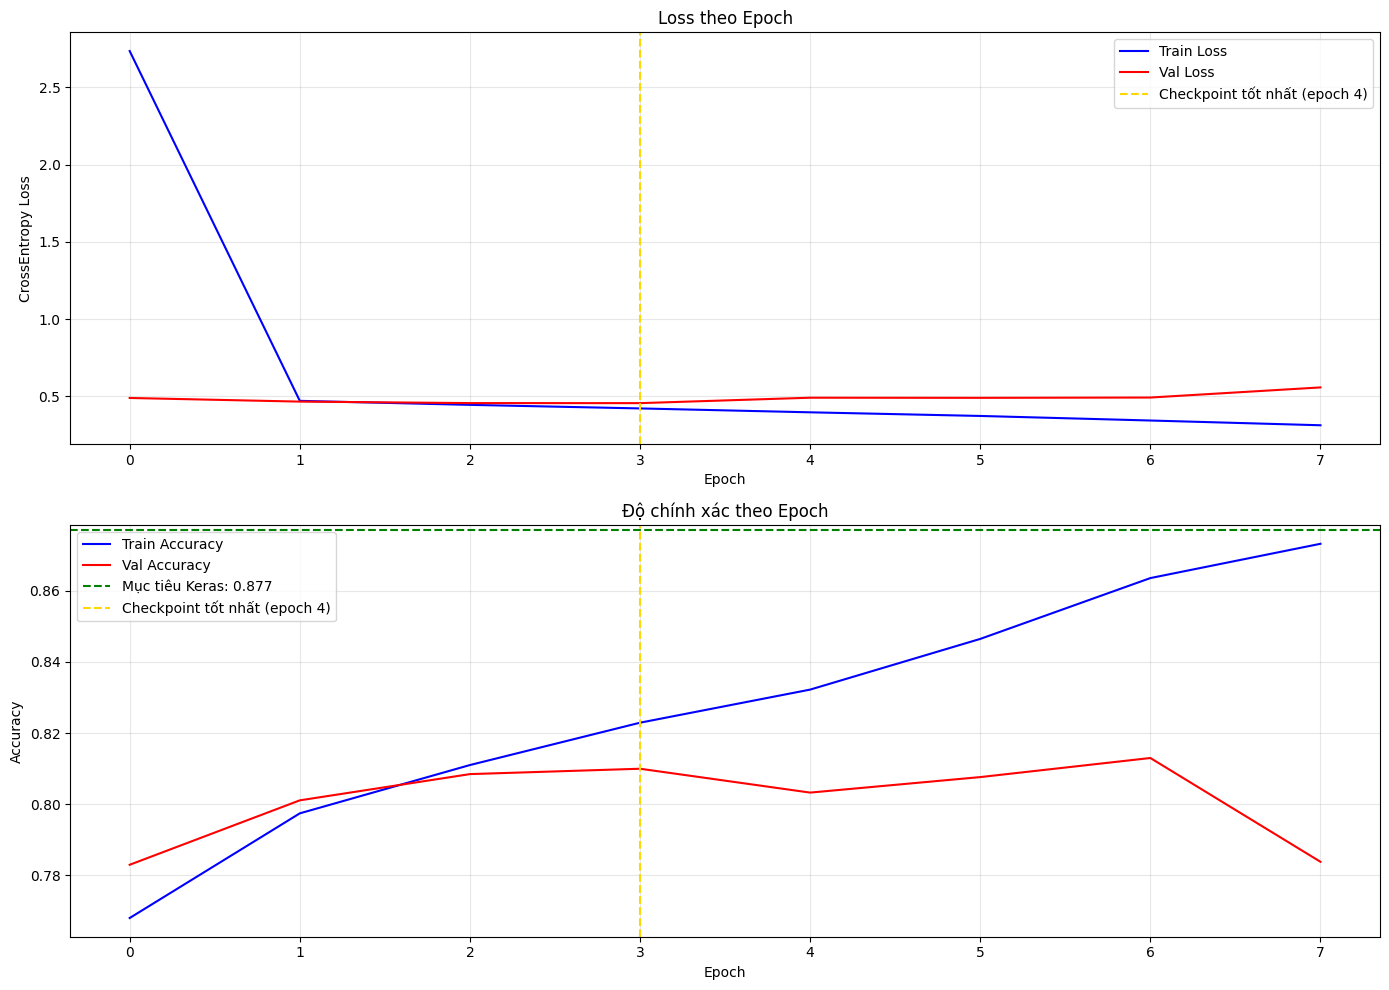

In [19]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Biểu đồ Loss
axes[0].plot(history['train_loss'], 'b-', label='Train Loss')
axes[0].plot(history['val_loss'], 'r-', label='Val Loss')
axes[0].axvline(x=best_epoch-1, color='gold', linestyle='--', label=f'Checkpoint tốt nhất (epoch {best_epoch})')
axes[0].set_title('Loss theo Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('CrossEntropy Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Biểu đồ Accuracy
axes[1].plot(history['train_acc'], 'b-', label='Train Accuracy')
axes[1].plot(history['val_acc'], 'r-', label='Val Accuracy')
axes[1].axhline(y=0.877, color='green', linestyle='--', label='Mục tiêu Keras: 0.877')
axes[1].axvline(x=best_epoch-1, color='gold', linestyle='--', label=f'Checkpoint tốt nhất (epoch {best_epoch})')
axes[1].set_title('Độ chính xác theo Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## **Tải Checkpoint & Đánh giá Lại**

In [20]:
# === Tải mô hình tốt nhất ===
checkpoint = torch.load('checkpoints/best_model.pth')
model.load_state_dict(checkpoint['model_state_dict'])

print(f"Tải checkpoint từ Epoch {checkpoint['epoch']}")
print(f"   val_loss: {checkpoint['val_loss']:.4f}")
print(f"   val_acc:  {checkpoint['val_acc']:.4f}")

# === Đánh giá cuối trên tập Validation ===
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for X_batch, y_batch in val_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        outputs = model(X_batch)
        _, predicted = torch.max(outputs.data, 1)
        total += y_batch.size(0)
        correct += (predicted == y_batch).sum().item()

final_acc = correct / total
print(f"\nĐộ chính xác cuối trên tập Validation: {final_acc:.4f}")
print(f"   So sánh với Keras: {'ĐẠT' if final_acc >= 0.877 else 'CHƯA ĐẠT'} mục tiêu 0.877")


Tải checkpoint từ Epoch 4
   val_loss: 0.4563
   val_acc:  0.8100

Độ chính xác cuối trên tập Validation: 0.8100
   So sánh với Keras: CHƯA ĐẠT mục tiêu 0.877


In [22]:
print("=== TỔNG HỢP THÔNG SỐ MÔ HÌNH ===")
summary(model, input_size=(1, 1, 64, 64), col_names=["input_size", "output_size", "num_params", "kernel_size"])

=== TỔNG HỢP THÔNG SỐ MÔ HÌNH ===


Layer (type:depth-idx)                   Input Shape               Output Shape              Param #                   Kernel Shape
GenderCNN                                [1, 1, 64, 64]            [1, 2]                    --                        --
├─Conv2d: 1-1                            [1, 1, 64, 64]            [1, 32, 64, 64]           320                       [3, 3]
├─ReLU: 1-2                              [1, 32, 64, 64]           [1, 32, 64, 64]           --                        --
├─MaxPool2d: 1-3                         [1, 32, 64, 64]           [1, 32, 32, 32]           --                        2
├─Conv2d: 1-4                            [1, 32, 32, 32]           [1, 64, 32, 32]           18,496                    [3, 3]
├─ReLU: 1-5                              [1, 64, 32, 32]           [1, 64, 32, 32]           --                        --
├─MaxPool2d: 1-6                         [1, 64, 32, 32]           [1, 64, 16, 16]           --                        2
├─Flatte